<a href="https://colab.research.google.com/github/NietoEmmanuel/SIMULACION-II/blob/main/Modelo_SIR_con_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**AJUSTE DE PARÁMETROS DEL MODELO SIR**


# Modelo SIR
$\frac{dS}{dt}= -aSI$

$\frac{dI}{dt}= aSI - bI$

$\frac{dR}{dt}= bI$

Con:
* SUSCEPTIBLES (**S**): Personas sanas que aún no han contraído la enfermedad y pueden infectarse.
*  INFECTADOS (**I)**: Personas que tienen la enfermedad y pueden transmitirla a los susceptibles.
*  REMOVIDOS (**R**): Personas que se han curado o fallecido, según la versión clásica.
* a: Tasa de transmisión.
* b: Tasa media de recuperación.


Para este trabajo hallaremos los valores de a y b, para esto estaremos haciendo:
1.   Graficar datos.
2.   Programar la solución numérica del modelo SIR, con parámetros libres.
3.   Plantear un ajuste por mínimos cuadrados , $X^{2}$(a,b)
4.   Usar el método MCMC (Metropolis-Hastings) para optimizar $X^{2}$.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# 1. Graficar datos

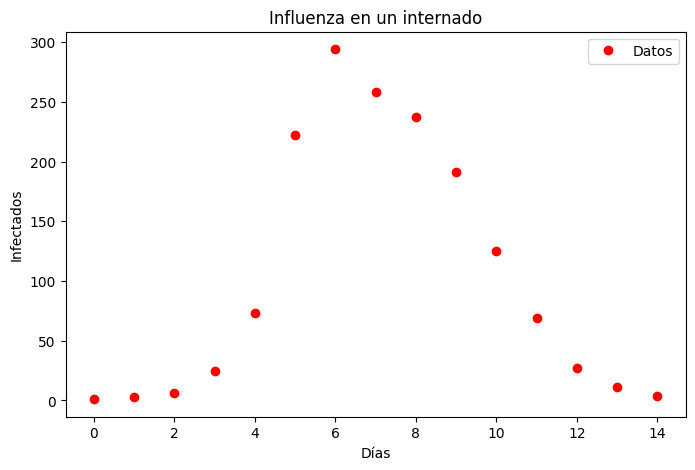

In [18]:
# datos de infectados por día
dias = np.arange(15)
infectados = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

plt.figure(figsize=(8, 5))
plt.plot(dias, infectados, 'ro', label='Datos')
plt.xlabel("Días")
plt.ylabel("Infectados")
plt.title("Influenza en un internado")
plt.legend()
plt.show()

# 2. Programar la solución numérica del modelo SIR, con parámetros libres.

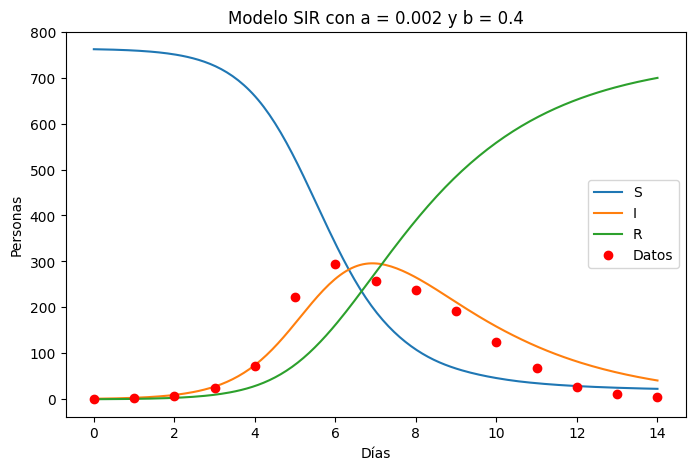

In [19]:
# ecuaciones del modelo SIR
def sir(t, y, a, b):
    S, I, R = y
    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I
    return [dS, dI, dR]

# resuelve el modelo para unos valores de a y b
def resolver(a, b, t):
    sol = solve_ivp(sir, (0, 14), [762, 1, 0], t_eval=t, args=(a, b))
    return sol.y

# prueba con valores libres.
t = np.linspace(0, 14, 200)
S, I, R = resolver(0.002, 0.4, t)

plt.figure(figsize=(8, 5))
plt.plot(t, S, label='S')
plt.plot(t, I, label='I')
plt.plot(t, R, label='R')
plt.plot(dias, infectados, 'ro', label='Datos')
plt.xlabel("Días")
plt.ylabel("Personas")
plt.title("Modelo SIR con a = 0.002 y b = 0.4")
plt.legend()
plt.show()

# 3. Plantear un ajuste por mínimos cuadrados, $X^{2}$ (a,b)

In [15]:
# X²(a,b): suma de las diferencias al cuadrado entre los datos y el modelo
def x2(parametros):
    a, b = parametros
    I_modelo = resolver(a, b, dias)[1]
    return np.sum((infectados - I_modelo)**2)

# buscamos el mínimo empezando en a = 0.002 y b = 0.4
resultado = minimize(x2, [0.002, 0.4], method='Nelder-Mead', options={'xatol': 1e-8, 'fatol': 1e-8})
mejor_a, mejor_b = resultado.x

print("a =", mejor_a)
print("b =", mejor_b)

a = 0.0021803522024118555
b = 0.445535008977313


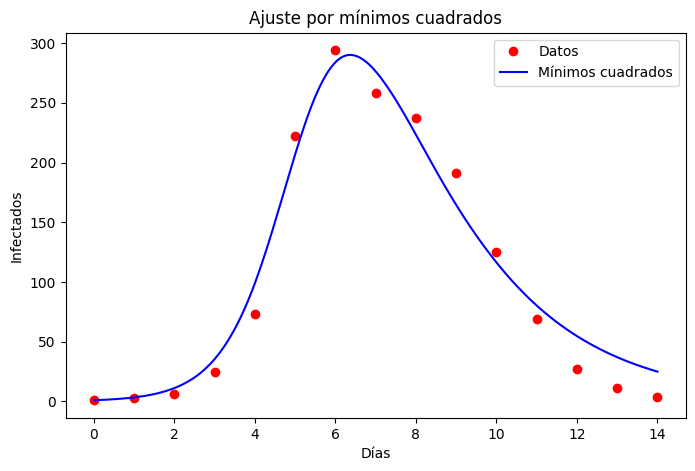

In [20]:
# modelo con los valores ajustados
I_ajuste = resolver(mejor_a, mejor_b, t)[1]

plt.figure(figsize=(8, 5))
plt.plot(dias, infectados, 'ro', label='Datos')
plt.plot(t, I_ajuste, 'b', label='Mínimos cuadrados')
plt.xlabel("Días")
plt.ylabel("Infectados")
plt.title("Ajuste por mínimos cuadrados")
plt.legend()
plt.show()

# 4. Usar el método MCMC (Metropolis-Hastings) para optimizar $X^{2}$

In [21]:
sigma = 10        # error de los datos
n = 5000          # número de pasos

# punto de partida
a_actual = 0.002
b_actual = 0.4
x2_actual = x2([a_actual, b_actual])

cadena_a = [a_actual]
cadena_b = [b_actual]

np.random.seed(42)
for i in range(n):
    a_nuevo = a_actual + np.random.normal(0, 0.00005)
    b_nuevo = b_actual + np.random.normal(0, 0.005)
    x2_nuevo = x2([a_nuevo, b_nuevo])

    # si X² baja, esto da más de 1 y se acepta siempre
    # si X² sube, se acepta solo algunas veces
    if np.random.rand() < np.exp(-(x2_nuevo - x2_actual) / (2 * sigma**2)):
        a_actual = a_nuevo
        b_actual = b_nuevo
        x2_actual = x2_nuevo

    cadena_a.append(a_actual)
    cadena_b.append(b_actual)

# quitamos los primeros 1000 pasos y sacamos el promedio
a_mcmc = np.mean(cadena_a[1000:])
b_mcmc = np.mean(cadena_b[1000:])

print("a =", a_mcmc)
print("b =", b_mcmc)

a = 0.0021789018030210494
b = 0.4434258625354725


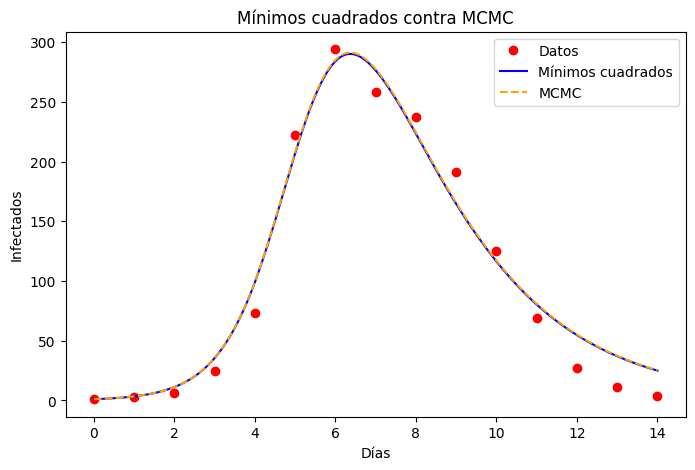

In [22]:
# modelo con los valores del MCMC, junto al de mínimos cuadrados
I_mcmc = resolver(a_mcmc, b_mcmc, t)[1]

plt.figure(figsize=(8, 5))
plt.plot(dias, infectados, 'ro', label='Datos')
plt.plot(t, I_ajuste, 'b', label='Mínimos cuadrados')
plt.plot(t, I_mcmc, 'orange', linestyle='--', label='MCMC')
plt.xlabel("Días")
plt.ylabel("Infectados")
plt.title("Mínimos cuadrados contra MCMC")
plt.legend()
plt.show()